In [33]:
import importlib
import mininn.layers
import mininn.containers
import mininn as mini

importlib.reload(mininn.layers)
importlib.reload(mininn.containers)
importlib.reload(mininn.training)
importlib.reload(mini)

print(mini.GroupNorm2D)

<class 'mininn.layers.GroupNorm2D'>


In [20]:
import torch
import mininn as mini
import inspect
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
from copy import copy
import time
import matplotlib.pyplot as plt
from IPython.display import display
from torch.utils.tensorboard import SummaryWriter
import math

device = "cuda"
data_root = "../data_1"
g = torch.Generator(device=device).manual_seed(42)

In [2]:
for in_ch, out_ch, stride, expected in [
    (64, 64, 1, (2, 64, 16, 16)),
    (64, 128, 2, (2, 128, 8, 8)),
]:
    block = mini.ResidualBlock(
        in_ch, out_ch,
        stride=stride,
        device=device,
    )

    x = torch.randn(
        2, in_ch, 16, 16,
        device=device,
        requires_grad=True,
    )

    block.train()
    y = block(x)

    assert tuple(y.shape) == expected
    assert torch.isfinite(y).all()
    assert (y >= 0).all()  # Final ReLU

    y.square().mean().backward()

    assert x.grad is not None
    assert torch.isfinite(x.grad).all()

    for p in block.parameters():
        assert p.grad is not None
        assert torch.isfinite(p.grad).all()

    print(
        f"{in_ch} → {out_ch}, stride={stride} | "
        f"Output: {tuple(y.shape)} | Checks passed"
    )

64 → 64, stride=1 | Output: (2, 64, 16, 16) | Checks passed
64 → 128, stride=2 | Output: (2, 128, 8, 8) | Checks passed


In [4]:
# Avoid different TF32 settings affecting the comparison.
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.set_float32_matmul_precision("highest")


class NativeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride):
        super().__init__()

        self.branch = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=True),
            nn.BatchNorm2d(out_ch, eps=1e-5, momentum=0.1),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=True),
            nn.BatchNorm2d(out_ch, eps=1e-5, momentum=0.1),
        )

        self.shortcut = (
            nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=True),
                nn.BatchNorm2d(out_ch, eps=1e-5, momentum=0.1),
            )
            if in_ch != out_ch or stride != 1
            else nn.Identity()
        )

    def forward(self, x):
        return torch.relu(self.branch(x) + self.shortcut(x))


def compare(name, actual, expected):
    assert actual is not None, f"{name}: missing gradient/tensor"
    assert expected is not None, f"{name}: missing reference"

    error = (actual - expected).abs().max().item()
    matches = torch.allclose(
        actual, expected, atol=1e-4, rtol=1e-3
    )

    print(f"{name}: matches={matches}, max_error={error:.3e}")
    assert matches, name


for in_ch, out_ch, stride in [(64, 64, 1), (64, 128, 2)]:
    custom = mini.ResidualBlock(
        in_ch, out_ch, stride=stride, device=device
    )
    native = NativeBlock(in_ch, out_ch, stride).to(device)

    conv_pairs = [
        (custom.branch.layers[0], native.branch[0]),
        (custom.branch.layers[3], native.branch[3]),
    ]
    bn_pairs = [
        (custom.branch.layers[1], native.branch[1]),
        (custom.branch.layers[4], native.branch[4]),
    ]

    if custom.shortcut is not None:
        conv_pairs.append(
            (custom.shortcut.layers[0], native.shortcut[0])
        )
        bn_pairs.append(
            (custom.shortcut.layers[1], native.shortcut[1])
        )

    with torch.no_grad():
        for c, n in conv_pairs:
            n.weight.copy_(c.weight)
            n.bias.copy_(c.bias)

        for c, n in bn_pairs:
            n.weight.copy_(c.gamma.reshape(-1))
            n.bias.copy_(c.beta.reshape(-1))
            n.running_mean.copy_(c.running_mean.reshape(-1))
            n.running_var.copy_(c.running_var.reshape(-1))

    custom.train()
    native.train()

    xc = torch.randn(
        2, in_ch, 16, 16, device=device, requires_grad=True
    )
    xn = xc.detach().clone().requires_grad_(True)

    yc = custom(xc)
    yn = native(xn)

    upstream = torch.randn_like(yc)
    yc.backward(upstream)
    yn.backward(upstream)

    print(f"\n{in_ch} → {out_ch}, stride={stride}")
    compare("Training output", yc, yn)
    compare("Input gradient", xc.grad, xn.grad)

    for i, (c, n) in enumerate(conv_pairs, 1):
        compare(f"Conv {i} weight gradient", c.weight.grad, n.weight.grad)
        compare(f"Conv {i} bias gradient", c.bias.grad, n.bias.grad)

    for i, (c, n) in enumerate(bn_pairs, 1):
        compare(
            f"BN {i} gamma gradient",
            c.gamma.grad.reshape(-1), n.weight.grad,
        )
        compare(
            f"BN {i} beta gradient",
            c.beta.grad.reshape(-1), n.bias.grad,
        )
        compare(
            f"BN {i} running mean",
            c.running_mean.reshape(-1), n.running_mean,
        )
        compare(
            f"BN {i} running variance",
            c.running_var.reshape(-1), n.running_var,
        )

    custom.eval()
    native.eval()

    with torch.no_grad():
        probe = torch.randn(2, in_ch, 16, 16, device=device)
        compare("Evaluation output", custom(probe), native(probe))

print("\nAll native-reference comparisons passed.")


64 → 64, stride=1
Training output: matches=True, max_error=2.491e-05
Input gradient: matches=True, max_error=1.431e-06
Conv 1 weight gradient: matches=True, max_error=3.433e-05
Conv 1 bias gradient: matches=True, max_error=8.106e-06
Conv 2 weight gradient: matches=True, max_error=1.588e-04
Conv 2 bias gradient: matches=True, max_error=9.537e-06
BN 1 gamma gradient: matches=True, max_error=1.216e-04
BN 1 beta gradient: matches=True, max_error=1.812e-05
BN 1 running mean: matches=True, max_error=3.260e-08
BN 1 running variance: matches=True, max_error=1.192e-07
BN 2 gamma gradient: matches=True, max_error=1.154e-04
BN 2 beta gradient: matches=True, max_error=4.768e-06
BN 2 running mean: matches=True, max_error=2.980e-08
BN 2 running variance: matches=True, max_error=5.960e-08
Evaluation output: matches=True, max_error=2.581e-05

64 → 128, stride=2
Training output: matches=True, max_error=2.974e-05
Input gradient: matches=True, max_error=1.907e-06
Conv 1 weight gradient: matches=True, ma

In [53]:
layer = mini.ConvSwiGLU(64, 64, device=device)

x = torch.randn(
    2, 64, 16, 16,
    device=device,
    requires_grad=True,
)

y = layer(x)
assert y.shape == x.shape
assert torch.isfinite(y).all()

y.square().mean().backward()

assert x.grad is not None
assert torch.isfinite(x.grad).all()

for p in layer.parameters():
    assert p.grad is not None
    assert torch.isfinite(p.grad).all()

print("Output:", tuple(y.shape))
print("Parameters:", sum(p.numel() for p in layer.parameters()))
print("Shape and gradient checks passed.")

Output: (2, 64, 16, 16)
Parameters: 8320
Shape and gradient checks passed.


In [54]:
layer.eval()

with torch.no_grad():
    expected = layer(x).clone()

# Clone so later weight changes don't alter the saved state.
state = {
    name: tensor.clone()
    for name, tensor in layer.state_dict().items()
}

restored = mini.ConvSwiGLU(64, 64, device=device)
restored.load_state_dict(state)
restored.eval()

with torch.no_grad():
    actual = restored(x)

assert torch.allclose(actual, expected)
assert set(state) == {"a.weight", "a.bias", "b.weight", "b.bias"}

print("Checkpoint round-trip passed.")

Checkpoint round-trip passed.


In [88]:
custom = mini.GroupNorm2D(64, groups=8, device=device)
native = nn.GroupNorm(8, 64, eps=custom.eps).to(device)

# Nontrivial affine parameters test more than the defaults.
with torch.no_grad():
    custom.gamma.uniform_(0.5, 1.5)
    custom.beta.uniform_(-0.2, 0.2)
    native.weight.copy_(custom.gamma.reshape(-1))
    native.bias.copy_(custom.beta.reshape(-1))

xc = torch.randn(
    2, 64, 8, 8, device=device, requires_grad=True
)
xn = xc.detach().clone().requires_grad_(True)

yc = custom(xc)
yn = native(xn)

upstream = torch.randn_like(yc)
yc.backward(upstream)
yn.backward(upstream)


def check(name, actual, expected):
    assert actual is not None and expected is not None
    error = (actual - expected).abs().max().item()
    matches = torch.allclose(
        actual, expected, atol=1e-4, rtol=1e-3
    )
    print(f"{name}: matches={matches}, max_error={error:.3e}")
    assert matches, name


check("Output", yc, yn)
check("Input gradient", xc.grad, xn.grad)
check(
    "Gamma gradient",
    custom.gamma.grad.reshape(-1),
    native.weight.grad,
)
check(
    "Beta gradient",
    custom.beta.grad.reshape(-1),
    native.bias.grad,
)

with torch.no_grad():
    custom.train()
    train_output = custom(xc).clone()

    custom.eval()
    eval_output = custom(xc).clone()

check("Train/eval equivalence", train_output, eval_output)

restored = mini.GroupNorm2D(64, groups=8, device=device)
restored.load_state_dict(custom.state_dict())

with torch.no_grad():
    check("Checkpoint round-trip", restored(xc), eval_output)

print("All GroupNorm checks passed.")

Output: matches=True, max_error=7.153e-07
Input gradient: matches=True, max_error=7.153e-07
Gamma gradient: matches=True, max_error=3.815e-06
Beta gradient: matches=True, max_error=3.815e-06
Train/eval equivalence: matches=True, max_error=0.000e+00
Checkpoint round-trip: matches=True, max_error=0.000e+00
All GroupNorm checks passed.


In [4]:
train_data = datasets.CIFAR100(
    root=data_root,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True,
    generator=torch.Generator().manual_seed(42),
    num_workers=0,
)

# Fetch once; reuse these exact tensors for every update.
images, labels = next(iter(loader))
images = images.to(device)
labels = labels.to(device)

print(images.shape)  # (32, 3, 32, 32)
print(labels.shape)  # (32,)
print(labels.min().item(), labels.max().item())  # within 0–99

torch.Size([32, 3, 32, 32])
torch.Size([32])
1 99


In [5]:
batch_size = 32

train_data = datasets.CIFAR100(
    root=data_root,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)

train_subset, val_subset = random_split(
    train_data,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42),
)

#Plain training data
plain_train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(43),
)

# Flip-only training dataset
flip_dataset = copy(train_data)
flip_dataset.transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

# Crop + flip training dataset
crop_dataset = copy(train_data)
crop_dataset.transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

flip_train_subset = Subset(flip_dataset, train_subset.indices)
crop_train_subset = Subset(crop_dataset, train_subset.indices)

augmented_train_loader = DataLoader(
    flip_train_subset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(43),
)

augmented_cropped_train_loader = DataLoader(
    crop_train_subset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(43),
)

train_loader_64 = DataLoader(
    crop_train_subset,
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(43),
)

# Evaluation: no random augmentation
train_loader = DataLoader(
    train_subset, batch_size=batch_size, shuffle=False
)
val_loader = DataLoader(
    val_subset, batch_size=batch_size, shuffle=False
)

test_dataset = datasets.CIFAR100(
    root=data_root,
    train=False,
    download=True,
    transform=transforms.ToTensor(),
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

# Verify the split actually used for training.
train_ids = set(train_subset.indices)
val_ids = set(val_subset.indices)

assert train_ids.isdisjoint(val_ids)
assert set(crop_train_subset.indices) == train_ids
assert set(flip_train_subset.indices) == train_ids

for name, loader in [
    ("Flip training", augmented_train_loader),
    ("Crop training", augmented_cropped_train_loader),
    ("Validation", val_loader),
    ("Test", test_loader),
]:
    print(f"{name}: {len(loader.dataset):,}")

Flip training: 45,000
Crop training: 45,000
Validation: 5,000
Test: 10,000


In [34]:
def train_epochs(
    model_t,
    optimizer_t,
    checkpoint_name,
    data,
    epoch_start=1,
    n_epochs=20,
    lr_patience=3,
    lr_factor=0.1,
    min_lr=1e-6,
    min_delta=1e-4,
    writer=None,
    scheduler="plateau",
    cosine_start_lr=0.001,
    label_smoothing=0.0
):
    if scheduler not in ("plateau", "cosine"):
        raise ValueError("scheduler must be 'plateau' or 'cosine'.")
    if n_epochs < 1:
        raise ValueError("n_epochs must be positive.")
    if lr_patience < 1 or not 0 < lr_factor < 1:
        raise ValueError("Invalid plateau settings.")
    if not 0 <= min_lr <= cosine_start_lr:
        raise ValueError("Require 0 <= min_lr <= cosine_start_lr.")

    best_accuracy = float("-inf")
    best_loss = float("inf")
    bad_epochs = 0
    history = []

    last_checkpoint = (
        checkpoint_name.removesuffix(".pt") + "_last.pt"
    )

    for epoch_index, epoch in enumerate(
        range(epoch_start, epoch_start + n_epochs)
    ):
        # Set cosine LR BEFORE this epoch's training.
        if scheduler == "cosine":
            progress = epoch_index / max(n_epochs - 1, 1)
            optimizer_t.learning_rate = (
                min_lr
                + 0.5 * (cosine_start_lr - min_lr)
                * (1 + math.cos(math.pi * progress))
            )

        lr_used = optimizer_t.learning_rate

        if str(device).startswith("cuda"):
            torch.cuda.synchronize()
        started = time.perf_counter()

        train_loss = mini.train_one_epoch(
            model_t, data, optimizer_t, device, label_smoothing=label_smoothing
        )
        metrics = mini.evaluate(model_t, val_loader, device)

        if str(device).startswith("cuda"):
            torch.cuda.synchronize()
        seconds = time.perf_counter() - started

        if not all(math.isfinite(float(value)) for value in (
            train_loss, metrics["loss"], metrics["accuracy"]
        )):
            raise FloatingPointError(
                f"Nonfinite metric at epoch {epoch}."
            )

        # Save the best model independently of the scheduler.
        if metrics["accuracy"] > best_accuracy:
            best_accuracy = metrics["accuracy"]
            mini.save_checkpoint(
                checkpoint_name,
                model_t,
                optimizer=optimizer_t,
                epoch=epoch,
            )

        # Plateau LR changes apply to the NEXT epoch.
        if scheduler == "plateau":
            if metrics["loss"] < best_loss - min_delta:
                best_loss = metrics["loss"]
                bad_epochs = 0
            else:
                bad_epochs += 1

            if bad_epochs >= lr_patience:
                old_lr = optimizer_t.learning_rate
                new_lr = max(old_lr * lr_factor, min_lr)

                if new_lr < old_lr:
                    optimizer_t.learning_rate = new_lr
                    print(
                        f"LR reduced: {old_lr:.2e} → {new_lr:.2e} "
                        "(effective next epoch)"
                    )

                bad_epochs = 0

        history.append({
            "epoch": epoch,
            "train_loss": float(train_loss),
            "validation_loss": float(metrics["loss"]),
            "validation_accuracy_pct": float(metrics["accuracy"]),
            "learning_rate": lr_used,
            "next_learning_rate": optimizer_t.learning_rate,
            "epoch_seconds": seconds,
        })

        if writer is not None:
            writer.add_scalar("Loss/train", train_loss, epoch)
            writer.add_scalar(
                "Loss/validation", metrics["loss"], epoch
            )
            writer.add_scalar(
                "Accuracy/validation", metrics["accuracy"], epoch
            )
            writer.add_scalar("Learning_rate", lr_used, epoch)
            writer.flush()

        # Preserve the latest model and optimizer every epoch.
        mini.save_checkpoint(
            last_checkpoint,
            model_t,
            optimizer=optimizer_t,
            epoch=epoch,
        )

        print(
            f"Epoch {epoch} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {metrics['loss']:.4f} | "
            f"Val accuracy: {metrics['accuracy']:.2f}% | "
            f"LR: {lr_used:.2e} | Time: {seconds:.1f}s"
        )

    best_epoch = mini.load_checkpoint(
        checkpoint_name,
        model_t,
        optimizer=optimizer_t,
        device=device,
    )

    print(f"\nRestored best epoch: {best_epoch}")
    print(f"Best validation accuracy: {best_accuracy:.2f}%")

    return {
        "history": history,
        "best_epoch": best_epoch,
        "best_validation_accuracy_pct": best_accuracy,
        "scheduler_state": {
            "scheduler": scheduler,
            "best_loss": best_loss if scheduler == "plateau" else None,
            "bad_epochs": bad_epochs,
            "completed_epochs": n_epochs,
            "cosine_start_lr": cosine_start_lr,
            "min_lr": min_lr,
        },
        "last_checkpoint": last_checkpoint,
    }

In [7]:
def build_model(depth=18, activation="silu", use_swiglu=False):
    configurations = {
        18: (2, 2, 2, 2),
        34: (3, 4, 6, 3),
    }

    activations = {
        "relu": mini.ReLU,
        "silu": mini.SiLU,
    }

    if depth not in configurations:
        raise ValueError("Supported depths: 18 and 34.")

    if activation not in activations:
        raise ValueError("Supported activations: relu and silu.")

    activation_cls = activations[activation]

    layers = [
        mini.Conv2D(
            3, 64, 3, padding=1,
            device=device, generator=g,
        ),
        mini.BatchNorm2D(64, device=device),
        activation_cls(),
    ]

    in_channels = 64

    for stage_index, (out_channels, n_blocks) in enumerate(
        zip((64, 128, 256, 512), configurations[depth])
    ):
        for block_index in range(n_blocks):
            stride = (
                2 if stage_index > 0 and block_index == 0 else 1
            )

            layers.append(
                mini.ResidualBlock(
                    in_channels,
                    out_channels,
                    stride=stride,
                    activation=activation_cls,
                    use_swiglu=use_swiglu,
                    use_skip=True,
                    device=device,
                    generator=g,
                )
            )

            in_channels = out_channels

    layers.extend([
        mini.GlobalAvgPool2D(),
        mini.Linear(512, 100, device=device, generator=g),
    ])

    return mini.Sequential(layers) 

In [12]:
g.manual_seed(42)
model_resnet = build_model()

x = torch.randn(2, 3, 32, 32, device=device)
targets = torch.tensor([0, 99], device=device)

model_resnet.train()
logits = model_resnet(x)

assert logits.shape == (2, 100)

loss = torch.nn.functional.cross_entropy(logits, targets)
assert torch.isfinite(loss)

loss.backward()

params = model_resnet.parameters()

for i, p in enumerate(params):
    assert p.grad is not None, f"Parameter {i}: missing gradient"
    assert torch.isfinite(p.grad).all(), f"Parameter {i}: nonfinite gradient"

print("Output shape:", tuple(logits.shape))
print(f"Loss: {loss.item():.4f}")
print(f"Trainable parameters: {sum(p.numel() for p in params):,}")
print("All gradient checks passed.")

Output shape: (2, 100)
Loss: 6.6828
Trainable parameters: 11,224,932
All gradient checks passed.


In [13]:
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

optimizer_debug = mini.Adam(
    model_resnet.parameters(),
    learning_rate=0.001,
)

for step in range(201):
    model_resnet.train()
    optimizer_debug.zero_grad()

    logits = model_resnet(images)
    loss = torch.nn.functional.cross_entropy(logits, labels)

    if step in (0, 50, 100, 200):
        accuracy = (
            logits.argmax(dim=1) == labels
        ).float().mean().item() * 100

        print(
            f"Step {step:3d}/200 | "
            f"Loss: {loss.item():.6f} | "
            f"Batch accuracy: {accuracy:6.2f}%"
        )

    if step < 200:
        loss.backward()
        optimizer_debug.step()

Step   0/200 | Loss: 4.933933 | Batch accuracy:   3.12%
Step  50/200 | Loss: 0.000040 | Batch accuracy: 100.00%
Step 100/200 | Loss: 0.000019 | Batch accuracy: 100.00%
Step 200/200 | Loss: 0.000009 | Batch accuracy: 100.00%


In [15]:
g.manual_seed(42)
model_resnet_plain = build_model()

optimizer_resnet_plain = mini.Adam(
    model_resnet_plain.parameters(),
    learning_rate=0.001,
)

In [18]:
train_epochs(
    model_resnet_plain,
    optimizer_resnet_plain,
    checkpoint_name="best_resnet18_plain_adam_ep10.pt",
    data=plain_train_loader,
    epoch_start=1,
    n_epochs=10,
)

best_resnet18_plain_adam_ep10.pt
Epoch 1 | Train loss: 3.5021 | Val loss: 3.0437 | Val accuracy: 26.34% | Time: 95.2s
Epoch 2 | Train loss: 2.4621 | Val loss: 2.3941 | Val accuracy: 37.42% | Time: 100.0s
Epoch 3 | Train loss: 1.8907 | Val loss: 1.9740 | Val accuracy: 46.42% | Time: 97.6s
Epoch 4 | Train loss: 1.4757 | Val loss: 1.7688 | Val accuracy: 52.20% | Time: 82.9s
Epoch 5 | Train loss: 1.1055 | Val loss: 1.8134 | Val accuracy: 52.52% | Time: 90.3s
Epoch 6 | Train loss: 0.7430 | Val loss: 1.8019 | Val accuracy: 54.70% | Time: 96.4s
Epoch 7 | Train loss: 0.4541 | Val loss: 2.0373 | Val accuracy: 52.86% | Time: 95.9s
Epoch 8 | Train loss: 0.2797 | Val loss: 2.2495 | Val accuracy: 54.30% | Time: 97.9s
Epoch 9 | Train loss: 0.2116 | Val loss: 2.5027 | Val accuracy: 52.50% | Time: 100.3s
Epoch 10 | Train loss: 0.1823 | Val loss: 2.4735 | Val accuracy: 54.06% | Time: 92.6s

Restored epoch: 6
Training accuracy: 88.90%
Validation accuracy: 54.70%


In [20]:
optimizer_resnet_plain.learning_rate = 0.0001

In [ ]:
train_epochs(
    model_resnet_plain,
    optimizer_resnet_plain,
    checkpoint_name="best_resnet18_plain_adam_ep20.pt",
    data=plain_train_loader,
    epoch_start=11,
    n_epochs=10,
)

best_resnet18_plain_adam_ep20.pt
Epoch 11 | Train loss: 0.2462 | Val loss: 1.5546 | Val accuracy: 60.18% | Time: 95.8s
Epoch 12 | Train loss: 0.1339 | Val loss: 1.6055 | Val accuracy: 59.64% | Time: 101.3s
Epoch 13 | Train loss: 0.0800 | Val loss: 1.6881 | Val accuracy: 60.38% | Time: 102.6s
Epoch 14 | Train loss: 0.0466 | Val loss: 1.7557 | Val accuracy: 59.90% | Time: 101.8s
Epoch 15 | Train loss: 0.0284 | Val loss: 1.8313 | Val accuracy: 59.92% | Time: 101.5s
Epoch 16 | Train loss: 0.0189 | Val loss: 1.8757 | Val accuracy: 59.42% | Time: 100.6s
Epoch 17 | Train loss: 0.0138 | Val loss: 1.9757 | Val accuracy: 59.66% | Time: 106.3s
Epoch 18 | Train loss: 0.0108 | Val loss: 2.0299 | Val accuracy: 59.44% | Time: 94.1s
Epoch 19 | Train loss: 0.0079 | Val loss: 2.0778 | Val accuracy: 59.06% | Time: 96.9s
Epoch 20 | Train loss: 0.0079 | Val loss: 2.1449 | Val accuracy: 58.68% | Time: 100.4s

Restored epoch: 13
Training accuracy: 99.85%
Validation accuracy: 60.38%


In [6]:
g.manual_seed(42)
model_resnet_flip = build_model()

optimizer_resnet_flip = mini.Adam(
    model_resnet_flip.parameters(),
    learning_rate=0.001,
)

In [7]:
train_epochs(
    model_resnet_flip,
    optimizer_resnet_flip,
    checkpoint_name="best_resnet18_flip_adam_ep10.pt",
    data=augmented_train_loader,
    epoch_start=1,
    n_epochs=10,
)

best_resnet18_flip_adam_ep10.pt
Epoch 1 | Train loss: 3.4702 | Val loss: 2.7645 | Val accuracy: 30.02% | Time: 82.3s
Epoch 2 | Train loss: 2.4488 | Val loss: 2.3480 | Val accuracy: 38.26% | Time: 81.7s
Epoch 3 | Train loss: 1.9290 | Val loss: 1.9098 | Val accuracy: 47.34% | Time: 81.9s
Epoch 4 | Train loss: 1.5895 | Val loss: 1.6989 | Val accuracy: 53.68% | Time: 81.6s
Epoch 5 | Train loss: 1.3342 | Val loss: 1.6163 | Val accuracy: 55.08% | Time: 80.3s
Epoch 6 | Train loss: 1.1005 | Val loss: 1.6099 | Val accuracy: 55.98% | Time: 80.0s
Epoch 7 | Train loss: 0.9049 | Val loss: 1.5457 | Val accuracy: 58.14% | Time: 80.1s
Epoch 8 | Train loss: 0.7199 | Val loss: 1.6330 | Val accuracy: 58.40% | Time: 79.9s
Epoch 9 | Train loss: 0.5630 | Val loss: 1.6166 | Val accuracy: 59.46% | Time: 80.3s
Epoch 10 | Train loss: 0.4367 | Val loss: 1.7859 | Val accuracy: 58.58% | Time: 80.0s

Restored epoch: 9
Training accuracy: 89.11%
Validation accuracy: 59.46%


In [10]:
best_epoch = mini.load_checkpoint(
        "best_resnet18_flip_adam_ep10.pt",
        model_resnet_flip,
        optimizer=optimizer_resnet_flip,
        device=device
    )

In [11]:
optimizer_resnet_flip.learning_rate = 0.0001

In [12]:
train_epochs(
    model_resnet_flip,
    optimizer_resnet_flip,
    checkpoint_name="best_resnet18_flip_adam_ep20.pt",
    data=augmented_train_loader,
    epoch_start=11,
    n_epochs=10,
)

best_resnet18_flip_adam_ep20.pt
Epoch 11 | Train loss: 0.2590 | Val loss: 1.3748 | Val accuracy: 64.30% | Time: 79.8s
Epoch 12 | Train loss: 0.1792 | Val loss: 1.3772 | Val accuracy: 65.02% | Time: 79.5s
Epoch 13 | Train loss: 0.1389 | Val loss: 1.4168 | Val accuracy: 64.72% | Time: 79.5s
Epoch 14 | Train loss: 0.1048 | Val loss: 1.4535 | Val accuracy: 65.20% | Time: 81.7s
Epoch 15 | Train loss: 0.0788 | Val loss: 1.4990 | Val accuracy: 65.00% | Time: 84.4s
Epoch 16 | Train loss: 0.0612 | Val loss: 1.5318 | Val accuracy: 64.84% | Time: 80.3s
Epoch 17 | Train loss: 0.0453 | Val loss: 1.5789 | Val accuracy: 64.70% | Time: 81.4s
Epoch 18 | Train loss: 0.0362 | Val loss: 1.6201 | Val accuracy: 64.58% | Time: 84.2s
Epoch 19 | Train loss: 0.0299 | Val loss: 1.6648 | Val accuracy: 64.26% | Time: 83.9s
Epoch 20 | Train loss: 0.0230 | Val loss: 1.6930 | Val accuracy: 64.32% | Time: 84.6s

Restored epoch: 14
Training accuracy: 99.16%
Validation accuracy: 65.20%


In [16]:
g.manual_seed(42)
model_resnet_flip_crop = build_model()

optimizer_resnet_flip_crop = mini.Adam(
    model_resnet_flip_crop.parameters(),
    learning_rate=0.001,
)

In [17]:
train_epochs(
    model_resnet_flip_crop,
    optimizer_resnet_flip_crop,
    checkpoint_name="best_resnet18_flip_crop_adam_ep10.pt",
    data=augmented_cropped_train_loader,
    epoch_start=1,
    n_epochs=10,
)

best_resnet18_flip_crop_adam_ep10.pt
Epoch 1 | Train loss: 3.7486 | Val loss: 3.2559 | Val accuracy: 20.60% | Time: 82.2s
Epoch 2 | Train loss: 2.8736 | Val loss: 2.9499 | Val accuracy: 28.74% | Time: 81.5s
Epoch 3 | Train loss: 2.3516 | Val loss: 2.3511 | Val accuracy: 38.64% | Time: 81.4s
Epoch 4 | Train loss: 2.0022 | Val loss: 1.9109 | Val accuracy: 47.94% | Time: 81.9s
Epoch 5 | Train loss: 1.7371 | Val loss: 1.7960 | Val accuracy: 51.56% | Time: 82.9s
Epoch 6 | Train loss: 1.5448 | Val loss: 1.6091 | Val accuracy: 55.54% | Time: 82.4s
Epoch 7 | Train loss: 1.3973 | Val loss: 1.6562 | Val accuracy: 55.02% | Time: 82.4s
Epoch 8 | Train loss: 1.2490 | Val loss: 1.5122 | Val accuracy: 59.70% | Time: 83.5s
Epoch 9 | Train loss: 1.1359 | Val loss: 1.4077 | Val accuracy: 60.72% | Time: 85.4s
Epoch 10 | Train loss: 1.0352 | Val loss: 1.4393 | Val accuracy: 61.64% | Time: 84.2s

Restored epoch: 10
Training accuracy: 74.56%
Validation accuracy: 61.64%


In [18]:
optimizer_resnet_flip_crop.learning_rate = 0.0001

optimizer_resnet_flip_crop.learning_rate

0.0001

In [19]:
train_epochs(
    model_resnet_flip_crop,
    optimizer_resnet_flip_crop,
    checkpoint_name="best_resnet18_flip_crop_adam_ep20.pt",
    data=augmented_cropped_train_loader,
    epoch_start=11,
    n_epochs=10,
)

best_resnet18_flip_crop_adam_ep20.pt
Epoch 11 | Train loss: 0.7271 | Val loss: 1.1572 | Val accuracy: 68.08% | Time: 82.1s
Epoch 12 | Train loss: 0.6393 | Val loss: 1.1419 | Val accuracy: 68.38% | Time: 81.8s
Epoch 13 | Train loss: 0.5962 | Val loss: 1.1591 | Val accuracy: 68.84% | Time: 81.5s
Epoch 14 | Train loss: 0.5633 | Val loss: 1.1508 | Val accuracy: 69.40% | Time: 81.5s
Epoch 15 | Train loss: 0.5310 | Val loss: 1.1412 | Val accuracy: 69.26% | Time: 82.0s
Epoch 16 | Train loss: 0.5032 | Val loss: 1.1615 | Val accuracy: 69.18% | Time: 85.0s
Epoch 17 | Train loss: 0.4747 | Val loss: 1.1631 | Val accuracy: 69.38% | Time: 90.0s
Epoch 18 | Train loss: 0.4559 | Val loss: 1.1736 | Val accuracy: 69.06% | Time: 89.4s
Epoch 19 | Train loss: 0.4334 | Val loss: 1.1769 | Val accuracy: 69.52% | Time: 84.5s
Epoch 20 | Train loss: 0.4074 | Val loss: 1.1843 | Val accuracy: 69.58% | Time: 87.8s

Restored epoch: 20
Training accuracy: 91.76%
Validation accuracy: 69.58%


In [8]:
g.manual_seed(42)
model_resnet_plain_adamw = build_model()

optimizer_resnet_plain_adamw = mini.AdamW(
    model_resnet_plain_adamw.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001
)

In [9]:
train_epochs(
    model_resnet_plain_adamw,
    optimizer_resnet_plain_adamw,
    checkpoint_name="best_resnet18_plain_adamw_ep10.pt",
    data=plain_train_loader,
    epoch_start=1,
    n_epochs=10,
)

best_resnet18_plain_adamw_ep10.pt
Epoch 1 | Train loss: 3.4991 | Val loss: 2.8058 | Val accuracy: 29.44% | Time: 83.0s
Epoch 2 | Train loss: 2.4686 | Val loss: 2.2731 | Val accuracy: 40.06% | Time: 81.3s
Epoch 3 | Train loss: 1.9029 | Val loss: 1.9575 | Val accuracy: 47.04% | Time: 81.5s
Epoch 4 | Train loss: 1.4919 | Val loss: 1.7653 | Val accuracy: 52.50% | Time: 81.6s
Epoch 5 | Train loss: 1.1208 | Val loss: 1.7753 | Val accuracy: 53.32% | Time: 83.1s
Epoch 6 | Train loss: 0.7529 | Val loss: 1.8404 | Val accuracy: 54.34% | Time: 81.7s
Epoch 7 | Train loss: 0.4525 | Val loss: 2.0476 | Val accuracy: 53.54% | Time: 82.0s
Epoch 8 | Train loss: 0.2791 | Val loss: 2.3179 | Val accuracy: 52.24% | Time: 81.8s
Epoch 9 | Train loss: 0.2094 | Val loss: 2.4739 | Val accuracy: 51.86% | Time: 82.4s
Epoch 10 | Train loss: 0.1795 | Val loss: 2.5298 | Val accuracy: 52.82% | Time: 81.8s

Restored epoch: 6
Training accuracy: 88.24%
Validation accuracy: 54.34%


In [11]:
optimizer_resnet_plain_adamw.learning_rate = 0.0001

optimizer_resnet_plain_adamw.learning_rate

0.0001

In [12]:
train_epochs(
    model_resnet_plain_adamw,
    optimizer_resnet_plain_adamw,
    checkpoint_name="best_resnet18_plain_adamw_ep20.pt",
    data=plain_train_loader,
    epoch_start=11,
    n_epochs=10,
)

best_resnet18_plain_adamw_ep20.pt
Epoch 11 | Train loss: 0.2506 | Val loss: 1.5778 | Val accuracy: 59.78% | Time: 81.9s
Epoch 12 | Train loss: 0.1351 | Val loss: 1.6212 | Val accuracy: 59.48% | Time: 81.9s
Epoch 13 | Train loss: 0.0804 | Val loss: 1.6876 | Val accuracy: 59.60% | Time: 82.3s
Epoch 14 | Train loss: 0.0462 | Val loss: 1.7603 | Val accuracy: 59.46% | Time: 82.5s
Epoch 15 | Train loss: 0.0278 | Val loss: 1.8275 | Val accuracy: 58.98% | Time: 82.3s
Epoch 16 | Train loss: 0.0188 | Val loss: 1.9130 | Val accuracy: 58.96% | Time: 82.2s
Epoch 17 | Train loss: 0.0131 | Val loss: 1.9778 | Val accuracy: 59.14% | Time: 82.8s
Epoch 18 | Train loss: 0.0103 | Val loss: 2.0474 | Val accuracy: 58.70% | Time: 83.2s
Epoch 19 | Train loss: 0.0083 | Val loss: 2.1275 | Val accuracy: 59.12% | Time: 82.3s
Epoch 20 | Train loss: 0.0065 | Val loss: 2.1607 | Val accuracy: 58.66% | Time: 82.5s

Restored epoch: 11
Training accuracy: 98.23%
Validation accuracy: 59.78%


In [13]:
g.manual_seed(42)
model_resnet_flip_adamw = build_model()

optimizer_resnet_flip_adamw = mini.AdamW(
    model_resnet_flip_adamw.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001
)

In [14]:
train_epochs(
    model_resnet_flip_adamw,
    optimizer_resnet_flip_adamw,
    checkpoint_name="best_resnet18_flip_adamw_ep10.pt",
    data=augmented_train_loader,
    epoch_start=1,
    n_epochs=10,
)

best_resnet18_flip_adamw_ep10.pt
Epoch 1 | Train loss: 3.4854 | Val loss: 2.9090 | Val accuracy: 27.86% | Time: 82.1s
Epoch 2 | Train loss: 2.4929 | Val loss: 2.3414 | Val accuracy: 38.68% | Time: 84.0s
Epoch 3 | Train loss: 1.9694 | Val loss: 1.9634 | Val accuracy: 47.14% | Time: 82.6s
Epoch 4 | Train loss: 1.6242 | Val loss: 1.7445 | Val accuracy: 52.62% | Time: 83.1s
Epoch 5 | Train loss: 1.3586 | Val loss: 1.6811 | Val accuracy: 53.54% | Time: 83.4s
Epoch 6 | Train loss: 1.1207 | Val loss: 1.5731 | Val accuracy: 57.58% | Time: 82.8s
Epoch 7 | Train loss: 0.9164 | Val loss: 1.5992 | Val accuracy: 57.34% | Time: 83.3s
Epoch 8 | Train loss: 0.7337 | Val loss: 1.6497 | Val accuracy: 58.12% | Time: 82.9s
Epoch 9 | Train loss: 0.5678 | Val loss: 1.6843 | Val accuracy: 58.70% | Time: 83.4s
Epoch 10 | Train loss: 0.4479 | Val loss: 1.8662 | Val accuracy: 58.44% | Time: 82.9s

Restored epoch: 9
Training accuracy: 88.60%
Validation accuracy: 58.70%


In [15]:
optimizer_resnet_flip_adamw.learning_rate = 0.0001

optimizer_resnet_flip_adamw.learning_rate

0.0001

In [16]:
train_epochs(
    model_resnet_flip_adamw,
    optimizer_resnet_flip_adamw,
    checkpoint_name="best_resnet18_flip_adamw_ep20.pt",
    data=augmented_train_loader,
    epoch_start=11,
    n_epochs=10,
)

best_resnet18_flip_adamw_ep20.pt
Epoch 11 | Train loss: 0.2637 | Val loss: 1.4021 | Val accuracy: 63.88% | Time: 100.1s
Epoch 12 | Train loss: 0.1829 | Val loss: 1.4162 | Val accuracy: 64.46% | Time: 97.5s
Epoch 13 | Train loss: 0.1393 | Val loss: 1.4362 | Val accuracy: 64.54% | Time: 103.3s
Epoch 14 | Train loss: 0.1065 | Val loss: 1.4823 | Val accuracy: 64.48% | Time: 100.5s
Epoch 15 | Train loss: 0.0796 | Val loss: 1.5349 | Val accuracy: 64.26% | Time: 94.7s
Epoch 16 | Train loss: 0.0617 | Val loss: 1.5783 | Val accuracy: 64.66% | Time: 94.9s
Epoch 17 | Train loss: 0.0476 | Val loss: 1.5941 | Val accuracy: 63.92% | Time: 97.8s
Epoch 18 | Train loss: 0.0369 | Val loss: 1.6564 | Val accuracy: 64.52% | Time: 95.3s
Epoch 19 | Train loss: 0.0288 | Val loss: 1.7238 | Val accuracy: 63.92% | Time: 95.6s
Epoch 20 | Train loss: 0.0242 | Val loss: 1.7291 | Val accuracy: 64.08% | Time: 93.0s

Restored epoch: 16
Training accuracy: 99.69%
Validation accuracy: 64.66%


In [17]:
g.manual_seed(42)
model_resnet_flip_crop_adamw = build_model()

optimizer_resnet_flip_crop_adamw = mini.AdamW(
    model_resnet_flip_crop_adamw.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001
)

In [18]:
train_epochs(
    model_resnet_flip_crop_adamw,
    optimizer_resnet_flip_crop_adamw,
    checkpoint_name="best_resnet18_flip_crop_adamw_ep10.pt",
    data=augmented_cropped_train_loader,
    epoch_start=1,
    n_epochs=10,
)

best_resnet18_flip_crop_adamw_ep10.pt
Epoch 1 | Train loss: 3.7107 | Val loss: 3.2270 | Val accuracy: 22.12% | Time: 83.1s
Epoch 2 | Train loss: 2.8297 | Val loss: 2.6850 | Val accuracy: 33.58% | Time: 82.9s
Epoch 3 | Train loss: 2.3049 | Val loss: 2.2079 | Val accuracy: 41.00% | Time: 83.5s
Epoch 4 | Train loss: 1.9616 | Val loss: 1.8834 | Val accuracy: 48.78% | Time: 86.3s
Epoch 5 | Train loss: 1.7121 | Val loss: 1.7542 | Val accuracy: 51.92% | Time: 87.8s
Epoch 6 | Train loss: 1.5198 | Val loss: 1.5975 | Val accuracy: 55.96% | Time: 87.2s
Epoch 7 | Train loss: 1.3717 | Val loss: 1.5200 | Val accuracy: 57.84% | Time: 86.4s
Epoch 8 | Train loss: 1.2422 | Val loss: 1.4867 | Val accuracy: 58.98% | Time: 86.8s
Epoch 9 | Train loss: 1.1351 | Val loss: 1.3849 | Val accuracy: 61.24% | Time: 86.8s
Epoch 10 | Train loss: 1.0313 | Val loss: 1.4045 | Val accuracy: 60.46% | Time: 89.8s

Restored epoch: 9
Training accuracy: 73.88%
Validation accuracy: 61.24%


In [19]:
optimizer_resnet_flip_crop_adamw.learning_rate = 0.0001

optimizer_resnet_flip_crop_adamw.learning_rate

0.0001

In [22]:
train_epochs(
    model_resnet_flip_crop_adamw,
    optimizer_resnet_flip_crop_adamw,
    checkpoint_name="best_resnet18_flip_crop_adamw_ep19.pt",
    data=augmented_cropped_train_loader,
    epoch_start= 10,
    n_epochs=10,
)

best_resnet18_flip_crop_adamw_ep19.pt
Epoch 10 | Train loss: 0.8046 | Val loss: 1.1649 | Val accuracy: 66.96% | Time: 97.6s
Epoch 11 | Train loss: 0.7207 | Val loss: 1.1417 | Val accuracy: 67.52% | Time: 96.9s
Epoch 12 | Train loss: 0.6742 | Val loss: 1.1417 | Val accuracy: 68.28% | Time: 95.9s
Epoch 13 | Train loss: 0.6417 | Val loss: 1.1445 | Val accuracy: 68.52% | Time: 95.5s
Epoch 14 | Train loss: 0.6037 | Val loss: 1.1550 | Val accuracy: 68.34% | Time: 94.9s
Epoch 15 | Train loss: 0.5800 | Val loss: 1.1543 | Val accuracy: 68.90% | Time: 94.3s
Epoch 16 | Train loss: 0.5492 | Val loss: 1.1409 | Val accuracy: 68.86% | Time: 94.8s
Epoch 17 | Train loss: 0.5247 | Val loss: 1.1542 | Val accuracy: 69.22% | Time: 93.9s
Epoch 18 | Train loss: 0.5029 | Val loss: 1.1708 | Val accuracy: 69.20% | Time: 92.6s
Epoch 19 | Train loss: 0.4758 | Val loss: 1.1646 | Val accuracy: 69.12% | Time: 94.1s

Restored epoch: 17
Training accuracy: 88.63%
Validation accuracy: 69.22%


In [41]:
g.manual_seed(42)
model_resnet_silu_adam = build_model(activation="silu")

optimizer_resnet_silu_adam = mini.Adam(
    model_resnet_silu_adam.parameters(),
    learning_rate=0.001,
    # weight_decay=0.0001
)

In [42]:
train_epochs(
    model_resnet_silu_adam,
    optimizer_resnet_silu_adam,
    checkpoint_name="best_resnet18_silu_adam_stage1.pt",
    data=augmented_cropped_train_loader,
    epoch_start= 1,
    n_epochs=10,
)

best_resnet18_silu_adam_stage1.pt
Epoch 1 | Train loss: 3.9026 | Val loss: 3.3732 | Val accuracy: 19.46% | Time: 99.9s
Epoch 2 | Train loss: 3.0684 | Val loss: 2.6527 | Val accuracy: 31.90% | Time: 100.3s
Epoch 3 | Train loss: 2.4672 | Val loss: 2.2465 | Val accuracy: 41.58% | Time: 100.0s
Epoch 4 | Train loss: 2.0669 | Val loss: 1.8985 | Val accuracy: 49.24% | Time: 95.4s
Epoch 5 | Train loss: 1.7855 | Val loss: 1.8040 | Val accuracy: 51.44% | Time: 96.0s
Epoch 6 | Train loss: 1.5856 | Val loss: 1.6015 | Val accuracy: 56.84% | Time: 95.5s
Epoch 7 | Train loss: 1.4195 | Val loss: 1.5266 | Val accuracy: 57.42% | Time: 98.6s
Epoch 8 | Train loss: 1.2725 | Val loss: 1.4592 | Val accuracy: 59.62% | Time: 94.7s
Epoch 9 | Train loss: 1.1470 | Val loss: 1.4054 | Val accuracy: 61.40% | Time: 92.9s
Epoch 10 | Train loss: 1.0415 | Val loss: 1.4051 | Val accuracy: 62.50% | Time: 94.4s

Restored epoch: 10
Training accuracy: 75.19%
Validation accuracy: 62.50%


In [44]:
optimizer_resnet_silu_adam.learning_rate = 0.0001

optimizer_resnet_silu_adam.learning_rate

0.0001

In [45]:
train_epochs(
    model_resnet_silu_adam,
    optimizer_resnet_silu_adam,
    checkpoint_name="best_resnet18_silu_adam_stage2.pt",
    data=augmented_cropped_train_loader,
    epoch_start= 11,
    n_epochs=10,
)

best_resnet18_silu_adam_stage2.pt
Epoch 11 | Train loss: 0.7443 | Val loss: 1.1834 | Val accuracy: 67.70% | Time: 95.8s
Epoch 12 | Train loss: 0.6555 | Val loss: 1.1628 | Val accuracy: 68.66% | Time: 95.6s
Epoch 13 | Train loss: 0.6128 | Val loss: 1.1714 | Val accuracy: 68.84% | Time: 96.7s
Epoch 14 | Train loss: 0.5815 | Val loss: 1.1801 | Val accuracy: 68.86% | Time: 93.5s
Epoch 15 | Train loss: 0.5534 | Val loss: 1.1654 | Val accuracy: 69.32% | Time: 92.9s
Epoch 16 | Train loss: 0.5230 | Val loss: 1.1898 | Val accuracy: 68.68% | Time: 96.1s
Epoch 17 | Train loss: 0.5011 | Val loss: 1.1880 | Val accuracy: 69.42% | Time: 98.0s
Epoch 18 | Train loss: 0.4746 | Val loss: 1.1997 | Val accuracy: 69.54% | Time: 95.1s
Epoch 19 | Train loss: 0.4526 | Val loss: 1.2035 | Val accuracy: 69.16% | Time: 95.7s
Epoch 20 | Train loss: 0.4316 | Val loss: 1.2216 | Val accuracy: 69.14% | Time: 94.9s

Restored epoch: 18
Training accuracy: 90.02%
Validation accuracy: 69.54%


In [47]:
g.manual_seed(42)
model_resnet_silu_adamw = build_model(activation="silu")

optimizer_resnet_silu_adamw = mini.AdamW(
    model_resnet_silu_adamw.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001,
)

run_silu_adamw = train_epochs(
    model_resnet_silu_adamw,
    optimizer_resnet_silu_adamw,
    checkpoint_name="best_resnet18_silu_adamw_plateau.pt",
    data=augmented_cropped_train_loader,
    n_epochs=20,
)

Epoch 1 | Train loss: 3.8145 | Val loss: 3.2829 | Val accuracy: 19.84% | LR: 1.00e-03 | Time: 92.0s
Epoch 2 | Train loss: 2.9193 | Val loss: 2.5207 | Val accuracy: 35.06% | LR: 1.00e-03 | Time: 85.2s
Epoch 3 | Train loss: 2.3187 | Val loss: 2.1313 | Val accuracy: 43.42% | LR: 1.00e-03 | Time: 85.4s
Epoch 4 | Train loss: 1.9364 | Val loss: 1.8111 | Val accuracy: 51.22% | LR: 1.00e-03 | Time: 85.7s
Epoch 5 | Train loss: 1.6901 | Val loss: 1.6990 | Val accuracy: 53.08% | LR: 1.00e-03 | Time: 85.0s
Epoch 6 | Train loss: 1.4947 | Val loss: 1.5769 | Val accuracy: 56.96% | LR: 1.00e-03 | Time: 84.6s
Epoch 7 | Train loss: 1.3394 | Val loss: 1.5453 | Val accuracy: 58.46% | LR: 1.00e-03 | Time: 85.1s
Epoch 8 | Train loss: 1.2054 | Val loss: 1.3880 | Val accuracy: 61.34% | LR: 1.00e-03 | Time: 86.4s
Epoch 9 | Train loss: 1.0871 | Val loss: 1.3592 | Val accuracy: 63.40% | LR: 1.00e-03 | Time: 85.2s
Epoch 10 | Train loss: 0.9790 | Val loss: 1.3392 | Val accuracy: 63.80% | LR: 1.00e-03 | Time: 85.0s

In [134]:
g.manual_seed(42)
model_resnet_silu_34 = build_model(
    depth=34,
    activation="silu",
    use_swiglu=False,
)

optimizer_resnet_silu_34 = mini.AdamW(
    model_resnet_silu_34.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001,
)

parameter_count = sum(
    p.numel() for p in model_resnet_silu_34.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")


Trainable parameters: 21,336,804


In [135]:
writer = SummaryWriter("runs/resnet34_silu_adamw_bs32_40ep")

try:
    run_resnet34 = train_epochs(
        model_resnet_silu_34,
        optimizer_resnet_silu_34,
        checkpoint_name="best_resnet34_silu_adamw_bs32_40ep.pt",
        data=augmented_cropped_train_loader,
        n_epochs=40,
        writer=writer,
    )
finally:
    writer.close()

Epoch 1 | Train loss: 4.1506 | Val loss: 3.6145 | Val accuracy: 14.92% | LR: 1.00e-03 | Time: 155.8s
Epoch 2 | Train loss: 3.3786 | Val loss: 3.1279 | Val accuracy: 23.24% | LR: 1.00e-03 | Time: 169.8s
Epoch 3 | Train loss: 2.7589 | Val loss: 2.4812 | Val accuracy: 36.64% | LR: 1.00e-03 | Time: 174.0s
Epoch 4 | Train loss: 2.2670 | Val loss: 2.2342 | Val accuracy: 42.58% | LR: 1.00e-03 | Time: 174.6s
Epoch 5 | Train loss: 1.9237 | Val loss: 1.8937 | Val accuracy: 49.06% | LR: 1.00e-03 | Time: 174.7s
Epoch 6 | Train loss: 1.6797 | Val loss: 1.7130 | Val accuracy: 53.30% | LR: 1.00e-03 | Time: 177.1s
Epoch 7 | Train loss: 1.4906 | Val loss: 1.5779 | Val accuracy: 56.60% | LR: 1.00e-03 | Time: 154.2s
Epoch 8 | Train loss: 1.3330 | Val loss: 1.5465 | Val accuracy: 57.70% | LR: 1.00e-03 | Time: 196.5s
Epoch 9 | Train loss: 1.2139 | Val loss: 1.4410 | Val accuracy: 60.10% | LR: 1.00e-03 | Time: 156.2s
Epoch 10 | Train loss: 1.0967 | Val loss: 1.4054 | Val accuracy: 61.96% | LR: 1.00e-03 | Ti

KeyboardInterrupt: 

In [8]:
g.manual_seed(42)
model_resnet34_slow_decay = build_model(
    depth=34,
    activation="silu",
    use_swiglu=False,
)

optimizer_resnet34_slow_decay = mini.AdamW(
    model_resnet34_slow_decay.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001,
)

parameter_count = sum(
    p.numel() for p in model_resnet34_slow_decay.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {parameter_count:,}")


Trainable parameters: 21,336,804


In [11]:
for layer in model_resnet34_slow_decay.layers:
    if hasattr(layer, 'branch'):
        for layer2 in layer.branch.layers:
            print(layer2)
    else:
        print(layer)

In [12]:
model = model_resnet34_slow_decay

blocks = [
    layer for layer in model.layers
    if isinstance(layer, mini.ResidualBlock)
]

print("Residual blocks:", len(blocks))  # Expected: 16

for i, block in enumerate(blocks, 1):
    conv1 = block.branch.layers[0]
    conv2 = block.branch.layers[3]

    print(
        f"Block {i:2d} | "
        f"{conv1.weight.shape[1]} → {conv1.weight.shape[0]} | "
        f"stride={conv1.stride} | "
        f"conv2_out={conv2.weight.shape[0]} | "
        f"middle={type(block.branch.layers[2]).__name__} | "
        f"post_add={type(block.final_relu).__name__} | "
        f"skip={block.use_skip} | "
        f"projection={block.shortcut is not None}"
    )

Residual blocks: 16
Block  1 | 64 → 64 | stride=1 | conv2_out=64 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block  2 | 64 → 64 | stride=1 | conv2_out=64 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block  3 | 64 → 64 | stride=1 | conv2_out=64 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block  4 | 64 → 128 | stride=2 | conv2_out=128 | middle=SiLU | post_add=SiLU | skip=True | projection=True
Block  5 | 128 → 128 | stride=1 | conv2_out=128 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block  6 | 128 → 128 | stride=1 | conv2_out=128 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block  7 | 128 → 128 | stride=1 | conv2_out=128 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block  8 | 128 → 256 | stride=2 | conv2_out=256 | middle=SiLU | post_add=SiLU | skip=True | projection=True
Block  9 | 256 → 256 | stride=1 | conv2_out=256 | middle=SiLU | post_add=SiLU | skip=True | projection=False
Block 10 | 

In [8]:
print(augmented_cropped_train_loader.batch_size)

32


In [9]:
writer = SummaryWriter("runs/resnet34_silu_adamw_slow_decay_bs32_40ep")

try:
    run_model_resnet34_slow_decay = train_epochs(
        model_resnet34_slow_decay,
        optimizer_resnet34_slow_decay,
        checkpoint_name="best_resnet34_silu_adamw_slow_decay_bs32_40ep.pt",
        data=augmented_cropped_train_loader,
        n_epochs=40,
        writer=writer,
        lr_patience=5,
        lr_factor=0.5,
        min_lr=1e-5
    )
finally:
    writer.close()

Epoch 1 | Train loss: 4.1880 | Val loss: 3.6978 | Val accuracy: 13.18% | LR: 1.00e-03 | Time: 156.9s
Epoch 2 | Train loss: 3.4286 | Val loss: 3.0982 | Val accuracy: 23.88% | LR: 1.00e-03 | Time: 157.6s
Epoch 3 | Train loss: 2.7969 | Val loss: 2.5489 | Val accuracy: 34.06% | LR: 1.00e-03 | Time: 153.0s
Epoch 4 | Train loss: 2.2664 | Val loss: 2.0537 | Val accuracy: 44.88% | LR: 1.00e-03 | Time: 150.3s
Epoch 5 | Train loss: 1.9150 | Val loss: 1.9021 | Val accuracy: 48.62% | LR: 1.00e-03 | Time: 149.6s
Epoch 6 | Train loss: 1.6714 | Val loss: 1.6640 | Val accuracy: 54.24% | LR: 1.00e-03 | Time: 153.9s
Epoch 7 | Train loss: 1.4853 | Val loss: 1.5517 | Val accuracy: 56.40% | LR: 1.00e-03 | Time: 156.6s
Epoch 8 | Train loss: 1.3341 | Val loss: 1.4700 | Val accuracy: 58.86% | LR: 1.00e-03 | Time: 156.4s
Epoch 9 | Train loss: 1.2048 | Val loss: 1.4084 | Val accuracy: 60.80% | LR: 1.00e-03 | Time: 158.2s
Epoch 10 | Train loss: 1.0904 | Val loss: 1.4238 | Val accuracy: 61.68% | LR: 1.00e-03 | Ti

KeyboardInterrupt: 

In [13]:
custom = model_resnet34_slow_decay


class NativeBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride):
        super().__init__()

        self.branch = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=True),
            nn.BatchNorm2d(out_ch),
            nn.SiLU(),
            nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=True),
            nn.BatchNorm2d(out_ch),
        )

        self.shortcut = (
            nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=True),
                nn.BatchNorm2d(out_ch),
            )
            if in_ch != out_ch or stride != 1
            else nn.Identity()
        )

        self.activation = nn.SiLU()

    def forward(self, x):
        return self.activation(self.branch(x) + self.shortcut(x))


layers = [
    nn.Conv2d(3, 64, 3, padding=1, bias=True),
    nn.BatchNorm2d(64),
    nn.SiLU(),
]

in_ch = 64
for stage, (out_ch, count) in enumerate(
    zip((64, 128, 256, 512), (3, 4, 6, 3))
):
    for block_index in range(count):
        stride = 2 if stage > 0 and block_index == 0 else 1
        layers.append(NativeBlock(in_ch, out_ch, stride))
        in_ch = out_ch

layers.extend([
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(1),
    nn.Linear(512, 100),
])

native = nn.Sequential(*layers).double()

In [14]:
pairs = [
    ("stem.conv", custom.layers[0], native[0], "conv"),
    ("stem.bn", custom.layers[1], native[1], "bn"),
]

for i in range(16):
    c = custom.layers[3 + i]
    n = native[3 + i]

    pairs.extend([
        (f"block{i+1}.conv1", c.branch.layers[0], n.branch[0], "conv"),
        (f"block{i+1}.bn1", c.branch.layers[1], n.branch[1], "bn"),
        (f"block{i+1}.conv2", c.branch.layers[3], n.branch[3], "conv"),
        (f"block{i+1}.bn2", c.branch.layers[4], n.branch[4], "bn"),
    ])

    if c.shortcut is not None:
        pairs.extend([
            (f"block{i+1}.projection", c.shortcut.layers[0],
             n.shortcut[0], "conv"),
            (f"block{i+1}.projection_bn", c.shortcut.layers[1],
             n.shortcut[1], "bn"),
        ])

pairs.append(("classifier", custom.layers[-1], native[-1], "linear"))

In [15]:
def cpu_double(tensor):
    return tensor.detach().cpu().double()


with torch.no_grad():
    for name, c, n, kind in pairs:
        if kind == "bn":
            n.eps = c.eps
            n.momentum = c.momentum

            n.weight.copy_(cpu_double(c.gamma).reshape(-1))
            n.bias.copy_(cpu_double(c.beta).reshape(-1))
            n.running_mean.copy_(
                cpu_double(c.running_mean).reshape(-1)
            )
            n.running_var.copy_(
                cpu_double(c.running_var).reshape(-1)
            )

        elif kind == "linear":
            # mininn uses x @ weight; nn.Linear uses x @ weight.T.
            n.weight.copy_(cpu_double(c.weight).T)
            n.bias.copy_(cpu_double(c.bias).reshape(-1))

        else:
            n.weight.copy_(cpu_double(c.weight))
            n.bias.copy_(cpu_double(c.bias))

In [16]:
parameter = custom.parameters()[0]
custom_device = parameter.device
custom_dtype = parameter.dtype

# Preserve individual BatchNorm modes.
bn_layers = [c for _, c, _, kind in pairs if kind == "bn"]
previous_modes = [layer.training for layer in bn_layers]

images, _ = next(iter(val_loader))
xc = images[:2].to(
    device=custom_device, dtype=custom_dtype
).detach().requires_grad_(True)

xn = xc.detach().cpu().double().requires_grad_(True)

custom_params = []
native_params = []
parameter_names = []

for name, c, n, kind in pairs:
    custom_params.extend(
        [c.gamma, c.beta] if kind == "bn" else [c.weight, c.bias]
    )
    native_params.extend([n.weight, n.bias])
    parameter_names.extend([f"{name}.weight", f"{name}.bias"])

try:
    custom.eval()
    native.eval()

    yc = custom(xc)
    yn = native(xn)

    upstream = torch.randn_like(yc)

    custom_grads = torch.autograd.grad(
        yc, [xc] + custom_params, grad_outputs=upstream
    )
    native_grads = torch.autograd.grad(
        yn, [xn] + native_params,
        grad_outputs=upstream.cpu().double(),
    )
finally:
    for layer, previous_mode in zip(bn_layers, previous_modes):
        layer.training = previous_mode


def report(name, actual, expected):
    actual = cpu_double(actual)
    expected = cpu_double(expected)

    max_error = (actual - expected).abs().max().item()
    matches = torch.allclose(
        actual, expected, atol=1e-3, rtol=1e-2
    )

    print(f"{name}: matches={matches}, max_error={max_error:.3e}")
    return matches


passed = report("Output", yc, yn)
passed &= report("Input gradient", custom_grads[0], native_grads[0])

for index, (name, c, n, kind) in enumerate(pairs):
    for offset in (0, 1):
        gc = custom_grads[1 + 2 * index + offset]
        gn = native_grads[1 + 2 * index + offset]

        if kind == "linear" and offset == 0:
            gn = gn.T
        elif kind == "bn" or offset == 1:
            gn = gn.reshape(gc.shape)

        passed &= report(parameter_names[2 * index + offset], gc, gn)

print("\nAll comparisons passed:", passed)

Output: matches=True, max_error=6.702e-05
Input gradient: matches=True, max_error=1.337e-04
stem.conv.weight: matches=True, max_error=3.316e-04
stem.conv.bias: matches=True, max_error=3.886e-04
stem.bn.weight: matches=True, max_error=1.038e-03
stem.bn.bias: matches=True, max_error=3.930e-04
block1.conv1.weight: matches=True, max_error=6.283e-04
block1.conv1.bias: matches=True, max_error=2.274e-04
block1.bn1.weight: matches=True, max_error=3.952e-04
block1.bn1.bias: matches=True, max_error=2.425e-04
block1.conv2.weight: matches=True, max_error=7.691e-04
block1.conv2.bias: matches=True, max_error=3.709e-04
block1.bn2.weight: matches=True, max_error=2.622e-04
block1.bn2.bias: matches=True, max_error=3.721e-04
block2.conv1.weight: matches=True, max_error=7.879e-04
block2.conv1.bias: matches=True, max_error=3.386e-04
block2.bn1.weight: matches=True, max_error=7.522e-04
block2.bn1.bias: matches=True, max_error=3.431e-04
block2.conv2.weight: matches=True, max_error=1.554e-03
block2.conv2.bias

In [17]:
# Preserve weights, running statistics, and BN modes.
saved_custom_state = {
    name: tensor.detach().clone()
    for name, tensor in custom.state_dict().items()
}
saved_native_state = {
    name: tensor.detach().clone()
    for name, tensor in native.state_dict().items()
}

bn_pairs = [
    (name, c, n)
    for name, c, n, kind in pairs
    if kind == "bn"
]
saved_modes = [c.training for _, c, _ in bn_pairs]
saved_native_mode = native.training

images, labels = next(iter(train_loader))

parameter = custom.parameters()[0]
xc = images[:2].to(
    device=parameter.device,
    dtype=parameter.dtype,
).detach().requires_grad_(True)

xn = xc.detach().cpu().double().requires_grad_(True)
target_c = labels[:2].to(parameter.device)
target_n = labels[:2].cpu()

try:
    custom.train()
    native.train()

    yc = custom(xc)
    yn = native(xn)

    loss_c = torch.nn.functional.cross_entropy(yc, target_c)
    loss_n = torch.nn.functional.cross_entropy(yn, target_n)

    gc = torch.autograd.grad(loss_c, [xc] + custom_params)
    gn = torch.autograd.grad(loss_n, [xn] + native_params)

    passed = report("Training output", yc, yn)
    passed &= report("Training loss", loss_c, loss_n)
    passed &= report("Input gradient", gc[0], gn[0])

    failures = []

    for i, (name, c, n, kind) in enumerate(pairs):
        for offset, suffix in [(0, "weight"), (1, "bias")]:
            actual = gc[1 + 2 * i + offset]
            expected = gn[1 + 2 * i + offset]

            if kind == "linear" and offset == 0:
                expected = expected.T
            elif kind == "bn" or offset == 1:
                expected = expected.reshape(actual.shape)

            if not report(f"{name}.{suffix}", actual, expected):
                failures.append(f"{name}.{suffix}")

    for name, c, n in bn_pairs:
        passed &= report(
            f"{name}.running_mean",
            c.running_mean.reshape(-1),
            n.running_mean,
        )
        passed &= report(
            f"{name}.running_var",
            c.running_var.reshape(-1),
            n.running_var,
        )

    passed = passed and not failures
    print("\nAll training-mode comparisons passed:", passed)
    print("Parameter-gradient mismatches:", failures)

finally:
    custom.load_state_dict(saved_custom_state)
    native.load_state_dict(saved_native_state)

    for (_, c, _), mode in zip(bn_pairs, saved_modes):
        c.training = mode

    native.train(saved_native_mode)

Training output: matches=True, max_error=3.534e-06
Training loss: matches=True, max_error=3.439e-07
Input gradient: matches=True, max_error=6.869e-06
stem.conv.weight: matches=True, max_error=7.570e-06
stem.conv.bias: matches=True, max_error=1.788e-07
stem.bn.weight: matches=True, max_error=3.416e-06
stem.bn.bias: matches=True, max_error=1.565e-06
block1.conv1.weight: matches=True, max_error=5.858e-06
block1.conv1.bias: matches=True, max_error=3.725e-08
block1.bn1.weight: matches=True, max_error=3.832e-06
block1.bn1.bias: matches=True, max_error=1.151e-06
block1.conv2.weight: matches=True, max_error=5.824e-06
block1.conv2.bias: matches=True, max_error=2.980e-08
block1.bn2.weight: matches=True, max_error=2.214e-06
block1.bn2.bias: matches=True, max_error=8.651e-07
block2.conv1.weight: matches=True, max_error=3.714e-06
block2.conv1.bias: matches=True, max_error=1.583e-08
block2.bn1.weight: matches=True, max_error=2.190e-06
block2.bn1.bias: matches=True, max_error=6.944e-07
block2.conv2.w

In [18]:
torch.manual_seed(42)

custom_p = torch.randn(
    4, 3, dtype=torch.float64, requires_grad=True
)
native_p = custom_p.detach().clone().requires_grad_(True)

custom_opt = mini.AdamW(
    [custom_p],
    learning_rate=0.001,
    weight_decay=0.0001,
)
native_opt = torch.optim.AdamW(
    [native_p],
    lr=0.001,
    betas=(0.9, 0.999),
    eps=1e-8,
    weight_decay=0.0001,
    foreach=False,
)

for step in range(1, 11):
    # Also check an LR change without resetting moments.
    if step == 6:
        custom_opt.learning_rate = 0.0001
        native_opt.param_groups[0]["lr"] = 0.0001

    gradient = torch.randn_like(custom_p)
    custom_p.grad = gradient.clone()
    native_p.grad = gradient.clone()

    custom_opt.step()
    native_opt.step()

    native_state = native_opt.state[native_p]

    checks = {
        "parameters": torch.allclose(
            custom_p, native_p, atol=1e-12, rtol=1e-10
        ),
        "first moment": torch.allclose(
            custom_opt.first_moments[0],
            native_state["exp_avg"],
            atol=1e-12, rtol=1e-10,
        ),
        "second moment": torch.allclose(
            custom_opt.second_moments[0],
            native_state["exp_avg_sq"],
            atol=1e-12, rtol=1e-10,
        ),
    }

    error = (custom_p - native_p).abs().max().item()
    print(f"Step {step:2d} | max_error={error:.3e} | {checks}")
    assert all(checks.values())

print("AdamW update and LR-change checks passed.")

Step  1 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  2 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  3 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  4 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  5 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  6 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  7 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  8 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step  9 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
Step 10 | max_error=0.000e+00 | {'parameters': True, 'first moment': True, 'second moment': True}
AdamW update and LR-

In [19]:
import copy

# Uses custom_p and custom_opt from the previous test.
saved_parameter = custom_p.detach().clone()
saved_optimizer = copy.deepcopy(custom_opt.state_dict())

restored_p = saved_parameter.clone().requires_grad_(True)
restored_opt = mini.AdamW(
    [restored_p],
    learning_rate=0.5,  # Deliberately different.
    weight_decay=0.2,
)
restored_opt.load_state_dict(saved_optimizer)

assert restored_opt.t == custom_opt.t
assert restored_opt.learning_rate == custom_opt.learning_rate
assert restored_opt.weight_decay == custom_opt.weight_decay

for step in range(3):
    gradient = torch.randn_like(custom_p)

    custom_p.grad = gradient.clone()
    restored_p.grad = gradient.clone()

    custom_opt.step()
    restored_opt.step()

    torch.testing.assert_close(
        custom_p, restored_p, rtol=0, atol=0
    )
    torch.testing.assert_close(
        custom_opt.first_moments[0],
        restored_opt.first_moments[0],
        rtol=0, atol=0,
    )
    torch.testing.assert_close(
        custom_opt.second_moments[0],
        restored_opt.second_moments[0],
        rtol=0, atol=0,
    )
    assert custom_opt.t == restored_opt.t

print("Optimizer restoration and continuation passed.")

Optimizer restoration and continuation passed.


In [25]:
g.manual_seed(42)
model_resnet34_cosine = build_model(
    depth=34,
    activation="silu",
    use_swiglu=False,
)

optimizer_resnet34_cosine = mini.AdamW(
    model_resnet34_cosine.parameters(),
    learning_rate=0.001,
    weight_decay=0.0001,
)

writer = SummaryWriter(
    "runs/resnet34_silu_adamw_cosine_bs32_40ep"
)

In [26]:
try:
    run_resnet34_cosine = train_epochs(
        model_resnet34_cosine,
        optimizer_resnet34_cosine,
        checkpoint_name=(
            "best_resnet34_silu_adamw_cosine_bs32_40ep.pt"
        ),
        data=augmented_cropped_train_loader,
        n_epochs=40,
        scheduler="cosine",
        cosine_start_lr=0.001,
        min_lr=0.00001,
        writer=writer,
    )
finally:
    writer.close()

Epoch 1 | Train loss: 4.1699 | Val loss: 3.7055 | Val accuracy: 12.60% | LR: 1.00e-03 | Time: 150.5s
Epoch 2 | Train loss: 3.4655 | Val loss: 3.0701 | Val accuracy: 24.56% | LR: 9.98e-04 | Time: 154.3s
Epoch 3 | Train loss: 2.8708 | Val loss: 2.5883 | Val accuracy: 33.80% | LR: 9.94e-04 | Time: 167.5s
Epoch 4 | Train loss: 2.3789 | Val loss: 2.2372 | Val accuracy: 40.74% | LR: 9.86e-04 | Time: 164.3s
Epoch 5 | Train loss: 2.0445 | Val loss: 1.9970 | Val accuracy: 47.32% | LR: 9.75e-04 | Time: 165.9s
Epoch 6 | Train loss: 1.7805 | Val loss: 1.7498 | Val accuracy: 51.60% | LR: 9.60e-04 | Time: 163.5s
Epoch 7 | Train loss: 1.5768 | Val loss: 1.6647 | Val accuracy: 54.98% | LR: 9.43e-04 | Time: 161.2s
Epoch 8 | Train loss: 1.4176 | Val loss: 1.5427 | Val accuracy: 57.48% | LR: 9.23e-04 | Time: 161.1s
Epoch 9 | Train loss: 1.2681 | Val loss: 1.5057 | Val accuracy: 59.04% | LR: 9.01e-04 | Time: 159.9s
Epoch 10 | Train loss: 1.1441 | Val loss: 1.4405 | Val accuracy: 60.36% | LR: 8.76e-04 | Ti

In [30]:
g.manual_seed(42)
model_resnet34_cosine_wd1e3 = build_model(
    depth=34,
    activation="silu",
    use_swiglu=False,
)

optimizer_resnet34_cosine_wd1e3 = mini.AdamW(
    model_resnet34_cosine_wd1e3.parameters(),
    learning_rate=0.001,
    weight_decay=0.001,
)

writer = SummaryWriter(
    "runs/best_resnet34_silu_adamw_cosine_wd1e3_bs32_40ep"
)

In [31]:
try:
    run_resnet34_cosine_wd1e3  = train_epochs(
        model_resnet34_cosine_wd1e3,
        optimizer_resnet34_cosine_wd1e3,
        checkpoint_name=(
            "best_resnet34_silu_adamw_cosine_wd1e3_bs32_40ep.pt"
        ),
        data=augmented_cropped_train_loader,
        n_epochs=40,
        scheduler="cosine",
        cosine_start_lr=0.001,
        min_lr=0.00001,
        writer=writer,
    )
finally:
    writer.close()

Epoch 1 | Train loss: 4.1720 | Val loss: 3.6712 | Val accuracy: 13.54% | LR: 1.00e-03 | Time: 151.0s
Epoch 2 | Train loss: 3.3916 | Val loss: 2.9853 | Val accuracy: 25.74% | LR: 9.98e-04 | Time: 158.0s
Epoch 3 | Train loss: 2.7238 | Val loss: 2.3987 | Val accuracy: 38.26% | LR: 9.94e-04 | Time: 158.3s
Epoch 4 | Train loss: 2.2211 | Val loss: 2.0244 | Val accuracy: 45.42% | LR: 9.86e-04 | Time: 159.2s
Epoch 5 | Train loss: 1.8833 | Val loss: 1.7608 | Val accuracy: 51.94% | LR: 9.75e-04 | Time: 157.2s
Epoch 6 | Train loss: 1.6390 | Val loss: 1.6088 | Val accuracy: 55.60% | LR: 9.60e-04 | Time: 159.1s
Epoch 7 | Train loss: 1.4533 | Val loss: 1.5490 | Val accuracy: 57.52% | LR: 9.43e-04 | Time: 159.5s
Epoch 8 | Train loss: 1.3038 | Val loss: 1.4263 | Val accuracy: 60.48% | LR: 9.23e-04 | Time: 161.1s
Epoch 9 | Train loss: 1.1759 | Val loss: 1.4043 | Val accuracy: 61.66% | LR: 9.01e-04 | Time: 160.4s
Epoch 10 | Train loss: 1.0545 | Val loss: 1.3711 | Val accuracy: 62.82% | LR: 8.76e-04 | Ti

In [35]:
g.manual_seed(42)
model_resnet34_ls = build_model(
    depth=34,
    activation="silu",
    use_swiglu=False,
)

optimizer_resnet34_ls = mini.AdamW(
    model_resnet34_ls.parameters(),
    learning_rate=0.001,
    weight_decay=0.001,
)

writer = SummaryWriter(
    "runs/resnet34_silu_cosine_wd1e3_ls01_bs32_40ep"
)

try:
    run_resnet34_ls = train_epochs(
        model_resnet34_ls,
        optimizer_resnet34_ls,
        checkpoint_name=(
            "best_resnet34_silu_cosine_wd1e3_ls01_bs32_40ep.pt"
        ),
        data=augmented_cropped_train_loader,
        n_epochs=40,
        scheduler="cosine",
        cosine_start_lr=0.001,
        min_lr=1e-5,
        label_smoothing=0.1,
        writer=writer,
    )
finally:
    writer.close()

Epoch 1 | Train loss: 4.2765 | Val loss: 3.6207 | Val accuracy: 13.52% | LR: 1.00e-03 | Time: 178.0s
Epoch 2 | Train loss: 3.6141 | Val loss: 3.0330 | Val accuracy: 24.72% | LR: 9.98e-04 | Time: 160.9s
Epoch 3 | Train loss: 3.0996 | Val loss: 2.3988 | Val accuracy: 37.94% | LR: 9.94e-04 | Time: 153.6s
Epoch 4 | Train loss: 2.6918 | Val loss: 1.9797 | Val accuracy: 47.58% | LR: 9.86e-04 | Time: 162.4s
Epoch 5 | Train loss: 2.4101 | Val loss: 1.8047 | Val accuracy: 51.28% | LR: 9.75e-04 | Time: 153.0s
Epoch 6 | Train loss: 2.2191 | Val loss: 1.6458 | Val accuracy: 55.70% | LR: 9.60e-04 | Time: 152.6s
Epoch 7 | Train loss: 2.0656 | Val loss: 1.5563 | Val accuracy: 57.42% | LR: 9.43e-04 | Time: 163.9s
Epoch 8 | Train loss: 1.9371 | Val loss: 1.4513 | Val accuracy: 60.22% | LR: 9.23e-04 | Time: 162.7s
Epoch 9 | Train loss: 1.8259 | Val loss: 1.3951 | Val accuracy: 61.98% | LR: 9.01e-04 | Time: 169.4s
Epoch 10 | Train loss: 1.7281 | Val loss: 1.3348 | Val accuracy: 64.04% | LR: 8.76e-04 | Ti

In [41]:
run_resnet34_ls['history'][35]

{'epoch': 36,
 'train_loss': 0.8492647825876872,
 'validation_loss': 1.199516615629196,
 'validation_accuracy_pct': 73.7,
 'learning_rate': 3.5474461236162985e-05,
 'next_learning_rate': 3.5474461236162985e-05,
 'epoch_seconds': 173.49319436399674}

In [46]:
all_confidence = []
all_correct = []

model_resnet34_ls.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        logits = model_resnet34_ls(images)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predictions = probabilities.max(dim=1)
        
        all_confidence.append(confidence.cpu())
        all_correct.append((predictions == labels).cpu())
        
all_confidence = torch.cat(all_confidence)
all_correct = torch.cat(all_correct)
    
print("Examples:", all_correct.numel())
print(f"Accuracy: {all_correct.float().mean().item():.2%}")
print(f"Mean confidence: {all_confidence.mean().item():.2%}")

Examples: 5000
Accuracy: 73.70%
Mean confidence: 64.90%


In [48]:
mask = (all_confidence >=0.6) & (all_confidence < 0.7)

print("Examples: ", mask.sum().item())

if mask.any():
    bin_accuracy = all_correct[mask].float().mean().item()
    bin_confidence = all_confidence[mask].mean().item()
    
    print(f"Accuracy: {bin_accuracy:.2%}")
    print(f"Mean confidence: {bin_confidence:.2%}")

Examples:  399
Accuracy: 77.19%
Mean confidence: 65.37%


In [49]:
edges = torch.linspace(0, 1, 16)
ece = 0.0

for i in range(15):
    lower, upper = edges[i], edges[i+1]
    
    mask = (
        (all_confidence >= lower)
        & (
            (all_confidence < upper) if i < 14
            else (all_confidence <=upper)
        )
    )
    
    count = mask.sum().item()
    if count == 0:
        continue
    
    accuracy = all_correct[mask].float().mean().item()
    confidence = all_confidence[mask].mean().item()
    
    gap = abs(accuracy - confidence)
    
    ece +=(count/all_correct.numel()) * gap
    
    print(
        f"[{lower:.2f}, {upper:.2f}] | n={count:4d} | "
        f"Accuracy={accuracy:.2%} | Confidence={confidence:.2%}"
    )

print(f"\nECE: {ece:.2%}")

[0.00, 0.07] | n=   4 | Accuracy=0.00% | Confidence=6.28%
[0.07, 0.13] | n= 152 | Accuracy=17.76% | Confidence=10.98%
[0.13, 0.20] | n= 270 | Accuracy=26.30% | Confidence=16.86%
[0.20, 0.27] | n= 246 | Accuracy=36.18% | Confidence=23.45%
[0.27, 0.33] | n= 242 | Accuracy=45.04% | Confidence=29.89%
[0.33, 0.40] | n= 275 | Accuracy=49.82% | Confidence=36.76%
[0.40, 0.47] | n= 259 | Accuracy=52.12% | Confidence=43.39%
[0.47, 0.53] | n= 244 | Accuracy=60.25% | Confidence=50.02%
[0.53, 0.60] | n= 224 | Accuracy=69.20% | Confidence=56.64%
[0.60, 0.67] | n= 247 | Accuracy=75.71% | Confidence=63.47%
[0.67, 0.73] | n= 300 | Accuracy=80.67% | Confidence=70.09%
[0.73, 0.80] | n= 375 | Accuracy=87.73% | Confidence=76.90%
[0.80, 0.87] | n= 621 | Accuracy=91.30% | Confidence=83.74%
[0.87, 0.93] | n=1033 | Accuracy=96.32% | Confidence=90.13%
[0.93, 1.00] | n= 508 | Accuracy=97.44% | Confidence=95.16%

ECE: 8.81%


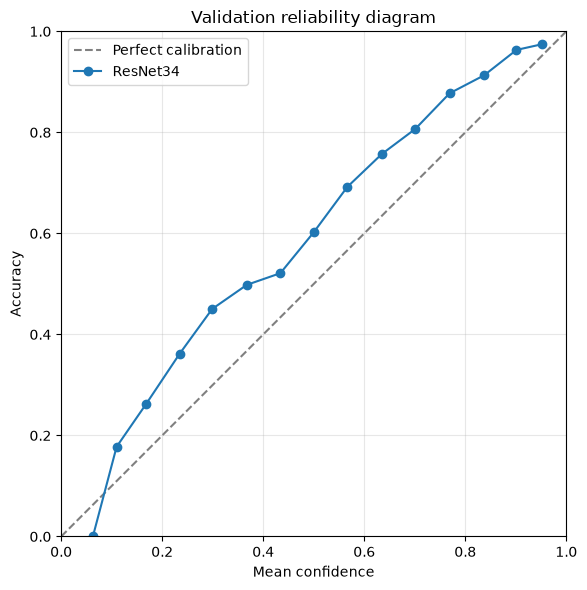

In [50]:
bin_confidences = []
bin_accuracies = []

for i in range(15):
    lower, upper = edges[i], edges[i + 1]
    mask = (all_confidence >= lower) & (
        (all_confidence < upper)
        if i < 14 else (all_confidence <= upper)
    )

    if mask.any():
        bin_confidences.append(all_confidence[mask].mean().item())
        bin_accuracies.append(all_correct[mask].float().mean().item())
        
fig, ax =  plt.subplots(figsize=(6,6))

ax.plot([0,1], [0,1], "--", color="gray", label="Perfect calibration")
ax.plot(bin_confidences, bin_accuracies, "o-", label="ResNet34")

ax.set(
    xlabel="Mean confidence",
    ylabel="Accuracy",
    title="Validation reliability diagram",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#Negative Log Likelihood
total_loss = 0.0
total_examples = 0.0

model_resnet34_ls.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        logits = model_resnet34_ls(images)
        
        total_loss += torch.nn.functional.cross_entropy(logits, labels, reduction="sum").item()
        total_examples += labels.numel()
        
nll = total_loss/total_examples
print(f"Validation NLL: {nll:.4f}")

Validation NLL: 1.1995


In [53]:
#Brier Score

total_brier = 0.0
total_examples = 0

model_resnet34_ls.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        probabilities = torch.softmax(model_resnet34_ls(images), dim=1)
        
        targets = torch.nn.functional.one_hot(
            labels, num_classes=probabilities.shape[1]
        ).to(probabilities.dtype)
        
        per_example = (probabilities - targets).square().sum(dim=1)
        
        total_brier += per_example.sum().item()
        total_examples += labels.numel()
        
brier = total_brier / total_examples
print(f"Validation Brier score: {brier:.4f}")

Validation Brier score: 0.3814


In [54]:
# CONFUSION MATRIX
num_classes = 100
confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.long
)

model_resnet34_ls.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        predictions = model_resnet34_ls(images).argmax(dim=1)
        
        indices = labels.cpu() * num_classes  + predictions.cpu()
        
        confusion += torch.bincount(
            indices, minlength=num_classes**2,
        ).reshape(num_classes,num_classes)
        
print("Shape:", confusion.shape)
print("Examples:", confusion.sum().item())
print("Correct:", confusion.diag().sum().item())

Shape: torch.Size([100, 100])
Examples: 5000
Correct: 3685


In [55]:
true_positives = confusion.diag().float()
support = confusion.sum(dim=1)
predicted_count = confusion.sum(dim=0)

recall = true_positives/support.clamp_min(1)
precision = true_positives/predicted_count.clamp_min(1)

present_classes = torch.where(support > 0)[0]
lowest = present_classes[recall[present_classes].argsort()[:10]]

class_names = val_loader.dataset.dataset.classes

for index in lowest.tolist():
    print(
        f"{class_names[index]:20s} | "
        f"Recall: {recall[index]:.2%} | "
        f"Precision: {precision[index]:.2%} | "
        f"Support: {support[index].item()}"
    )

lizard               | Recall: 38.30% | Precision: 52.94% | Support: 47
mouse                | Recall: 42.00% | Precision: 61.76% | Support: 50
seal                 | Recall: 42.22% | Precision: 46.34% | Support: 45
otter                | Recall: 45.65% | Precision: 38.89% | Support: 46
boy                  | Recall: 48.15% | Precision: 50.98% | Support: 54
girl                 | Recall: 48.98% | Precision: 57.14% | Support: 49
bowl                 | Recall: 50.00% | Precision: 66.67% | Support: 48
shrew                | Recall: 50.00% | Precision: 59.09% | Support: 52
flatfish             | Recall: 51.06% | Precision: 64.86% | Support: 47
shark                | Recall: 51.35% | Precision: 54.29% | Support: 37


In [56]:
for index in lowest.tolist():
    mistakes = confusion[index].clone()
    mistakes[index] = 0 # exclude correct preds
    
    if mistakes.sum() == 0:
        continue

    confused_with = mistakes.argmax().item()
    count = mistakes[confused_with].item()

    print(
        f"{class_names[index]:12s} → "
        f"{class_names[confused_with]:12s} | "
        f"{count} / {support[index].item()} examples"
    )

lizard       → dinosaur     | 4 / 47 examples
mouse        → hamster      | 6 / 50 examples
seal         → otter        | 8 / 45 examples
otter        → crocodile    | 5 / 46 examples
boy          → baby         | 8 / 54 examples
girl         → boy          | 8 / 49 examples
bowl         → plate        | 6 / 48 examples
shrew        → mouse        | 4 / 52 examples
flatfish     → ray          | 3 / 47 examples
shark        → turtle       | 3 / 37 examples


In [57]:
wrong_mask = ~all_correct
wrong_confidence = all_confidence[wrong_mask]

print("Incorrect predictions:", wrong_mask.sum().item())
print(f"Mean confidence when wrong: {wrong_confidence.mean().item():.2%}")

Incorrect predictions: 1315
Mean confidence when wrong: 39.60%
